# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [52]:
# # 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# # 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv  
# !rm ~/.cache/matplotlib -rf

In [53]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

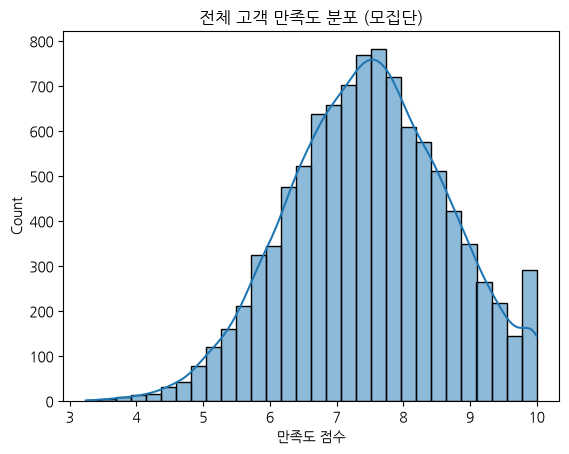

In [54]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [55]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
sample = df_pop['score'].sample(n=30)
print("표본 평균:", sample.mean())

표본 평균: 7.201974814386403


In [56]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
sample_means = [df_pop['score'].sample(n=30).mean() for i in range(500)]

print("저장된 개수:", len(sample_means))
print(sample_means[:5])

저장된 개수: 500
[np.float64(7.218309693351552), np.float64(7.576377244406479), np.float64(7.603218260346596), np.float64(7.258918899159289), np.float64(7.558775970877552)]


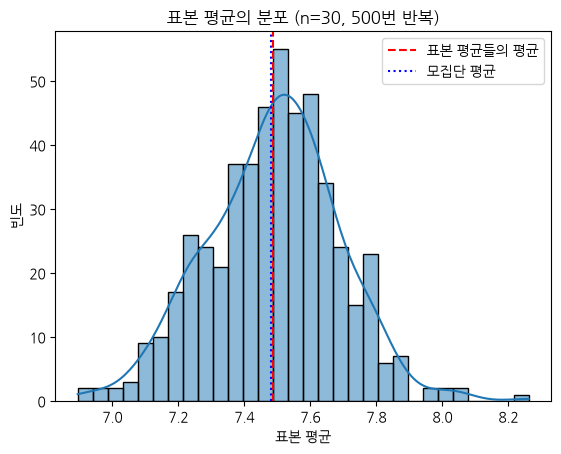

In [57]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
sns.histplot(sample_means, bins=30, kde=True)

plt.axvline(np.mean(sample_means), color='red', linestyle='--', label='표본 평균들의 평균')
plt.axvline(df_pop['score'].mean(), color='blue', linestyle=':', label='모집단 평균')

plt.title("표본 평균의 분포 (n=30, 500번 반복)")
plt.xlabel("표본 평균")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?

In [58]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 표본 평균들은 약 7.5 주변에 가장 많이 모여 있다. 모집단 평균(약 7.5)과 거의 같아서, 그래프에서 두 평균선이 거의 겹친다.
print("표본 평균들의 평균:", round(np.mean(sample_means), 3))
print("모집단 평균:", round(df_pop['score'].mean(), 3))

# [문제 2]
# 1번만 뽑으면 그 평균이 운에 따라 7.3이 될 수도, 7.7이 될 수도 있어서 믿기 어렵다. 
# 500번 반복하면 평균들이 어디에 모이는지, 얼마나 퍼지는지 전체 모양을 볼 수 있어서 진짜 평균을 더 믿을 만하게 추정할 수 있다.

# 비유: 국을 한 숟가락만 맛보면 우연히 건더기만 떠서 짜게 느낄 수 있지만, 500번 맛보면 국 맛을 확실히 알 수 있어요.

# [문제 3]
# 비슷하지만 완전히 같지는 않다. 
# 10,000명 중 30명을 무작위로 뽑기 때문에, 친구와 내가 뽑은 사람이 서로 다르다. 
# 뽑힌 사람이 다르면 평균도 조금씩 달라진다. 이렇게 표본마다 결과가 달라지는 것을 표본 오차라고 한다.

# [문제 4]
# 종 모양의 정규분포처럼 보인다. 표본 평균은 30명의 점수를 더해서 나눈 값이라, 
# 아주 높은 점수와 아주 낮은 점수가 서로 섞이며 상쇄된다. 
# 그래서 평균은 대부분 가운데(진짜 평균) 근처에 몰리고, 양 끝으로 갈수록 드물어진다. 이것을 중심극한정리라고 한다.

표본 평균들의 평균: 7.488
모집단 평균: 7.481


# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

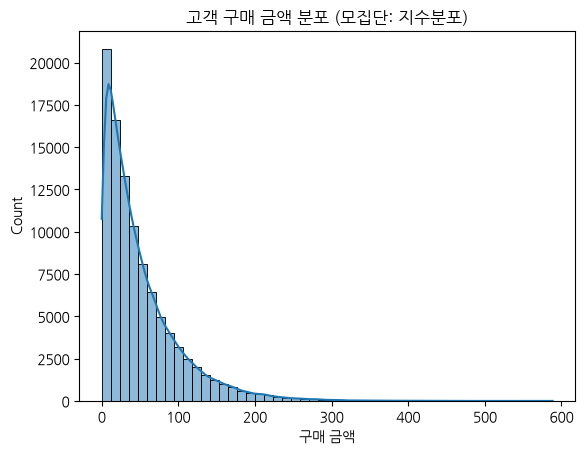

In [59]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [60]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

sample_means_5 = []

for i in range(1000):
    sample = np.random.choice(population, size=5)
    sample_means_5.append(sample.mean())

print("저장된 개수:", len(sample_means_5))
print("처음 5개:", [round(x, 2) for x in sample_means_5[:5]])
print(f"표본 평균들의 평균: {np.mean(sample_means_5):.2f}")

저장된 개수: 1000
처음 5개: [np.float64(31.99), np.float64(21.27), np.float64(54.76), np.float64(31.59), np.float64(81.0)]
표본 평균들의 평균: 49.81


In [61]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

results = {}

for n in [5, 30, 100]:
    results[n] = [np.random.choice(population, size=n).mean() for i in range(1000)]
    print(f"n={n:>3}  표본 평균들의 평균: {np.mean(results[n]):.2f}")

n=  5  표본 평균들의 평균: 50.61
n= 30  표본 평균들의 평균: 50.20
n=100  표본 평균들의 평균: 50.28


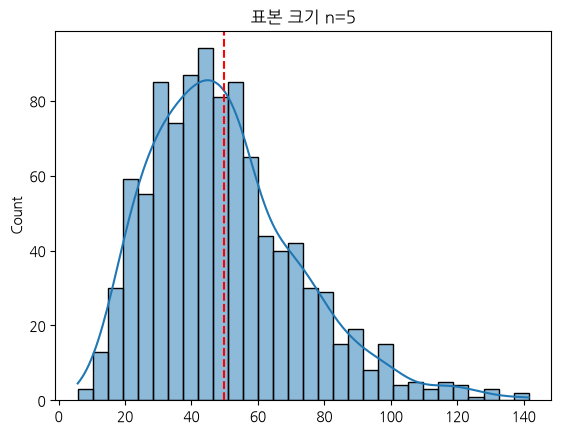

In [64]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

sns.histplot(sample_means_5, bins=30, kde=True)
plt.axvline(np.mean(sample_means_5), color='red', linestyle='--')
plt.title("표본 크기 n=5")
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

In [74]:
# # [문제 2]데이터를 어떻게 읽을까요?
# # 1. 표본 크기가 작을 때(5), 분포는 어떤 모양인가요?

# 완전한 종 모양이 아니라 왼쪽으로 쏠리고 오른쪽으로 꼬리가 긴 모양이다. 원래 모집단(지수분포)의 비대칭 모양이 아직 남아 있다. 
# 폭도 넓어서 표본 평균이 20대부터 100 넘게까지 넓게 흩어져 있다.

# 2. 표본 크기가 커질수록 모양은 어떻게 변하나요?

# n=30에서는 쏠림이 거의 사라지고 좌우 대칭인 종 모양에 가까워졌다. 
# n=100에서는 더 확실한 종 모양이 되었고, 가운데(약 50)에 더 뾰족하게 모였다.

# 3. 모집단은 비대칭인데 왜 평균들은 정규분포처럼 바뀌었나요?

# 평균은 여러 값을 더해서 나눈 것이라, 큰 값과 작은 값이 서로 상쇄된다. 
# 표본에 가끔 아주 큰 구매 금액이 섞여도, 나머지 평범한 값들과 섞이면서 평균은 가운데로 끌려온다.
# 표본이 클수록 이렇게 섞이는 값이 많아져서, 평균은 모집단 평균 근처에 많이 모이고 양 끝은 드물어진다. 그래서 종 모양이 된다.

# 비유: 5명만 모이면 부자 한 명이 평균을 확 끌어올리지만, 100명이 모이면 부자 한 명의 영향이 작아져요.

# 4. 이 실험으로 중심극한정리를 어떻게 이해했나요?

# 중심극한정리는 원래 데이터가 어떤 모양이든, 표본 크기가 충분히 크면 표본 평균의 분포는 정규분포에 가까워진다는 원리다. 
# 이번 실험에서 비대칭인 지수분포에서 시작했는데도, 표본 크기를 30, 100으로 키우자 표본 평균이 종 모양으로 바뀌는 것을 직접 확인했다. 
# 그래서 모집단 모양을 몰라도, 충분히 큰 표본의 평균으로 전체 평균을 추정할 수 있다는 것을 알게 되었다.

# 5. 표본 크기에 따라 분포의 넓이(흩어짐)는 어떻게 달라지나요?

# 표본 크기가 커질수록 분포가 좁아진다. 즉 표본 평균들이 모집단 평균 근처에 더 촘촘히 모인다. 
# 표본이 클수록 한 번 뽑은 표본 평균이 진짜 평균과 가까울 가능성이 높아서, 더 믿을 수 있다는 뜻이다.


In [75]:
import numpy as np

# 1. 모집단 만들기 (지수분포, 평균 50, 고객 10만 명)
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)

# 2. 표본 크기별로 표본 평균 1000개씩 뽑기
sample_means_5   = [np.random.choice(population, size=5).mean()   for i in range(1000)]
sample_means_30  = [np.random.choice(population, size=30).mean()  for i in range(1000)]
sample_means_100 = [np.random.choice(population, size=100).mean() for i in range(1000)]

# 3. 결과 출력
print(f"모집단 평균: {population.mean():.2f}   모집단 표준편차: {population.std():.2f}")
print()
print(f"n=  5  평균: {np.mean(sample_means_5):.2f}   표준편차: {np.std(sample_means_5):.2f}")
print(f"n= 30  평균: {np.mean(sample_means_30):.2f}   표준편차: {np.std(sample_means_30):.2f}")
print(f"n=100  평균: {np.mean(sample_means_100):.2f}   표준편차: {np.std(sample_means_100):.2f}")

모집단 평균: 50.23   모집단 표준편차: 50.32

n=  5  평균: 49.81   표준편차: 22.51
n= 30  평균: 50.36   표준편차: 9.21
n=100  평균: 50.27   표준편차: 4.79


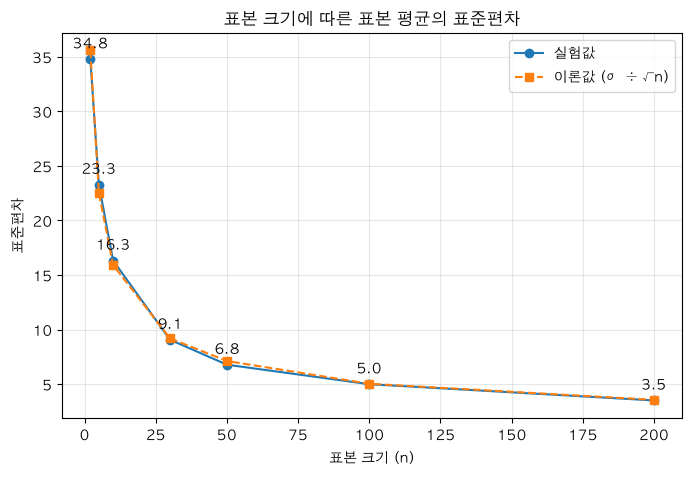

In [76]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "AppleGothic"    # 맥 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False

# 1. 모집단 만들기
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)

# 2. 표본 크기별 표준편차 구하기
sample_sizes = [2, 5, 10, 30, 50, 100, 200]
stds = []

for n in sample_sizes:
    means = [np.random.choice(population, size=n).mean() for i in range(1000)]
    stds.append(np.std(means))

# 3. 이론값 (모집단 표준편차 ÷ √n)
theory = [population.std() / np.sqrt(n) for n in sample_sizes]

# 4. 점 연결 그래프
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, stds, marker='o', label='실험값')
plt.plot(sample_sizes, theory, marker='s', linestyle='--', label='이론값 (σ ÷ √n)')

for n, s in zip(sample_sizes, stds):
    plt.text(n, s + 1, f"{s:.1f}", ha='center')

plt.title("표본 크기에 따른 표본 평균의 표준편차")
plt.xlabel("표본 크기 (n)")
plt.ylabel("표준편차")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

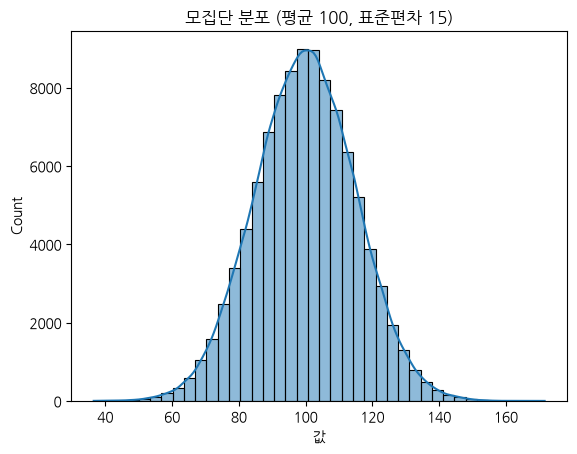

In [ ]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [77]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

import numpy as np
import pandas as pd

# 모집단 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 1. 결과를 담을 빈 리스트
sample_sizes = [10, 30, 100, 500]
std_list = []

# 2. 표본 크기마다 1000번 뽑고, 평균들의 표준편차 계산
for n in sample_sizes:
    means = []
    for i in range(1000):
        sample = np.random.choice(population, size=n)
        means.append(sample.mean())
    std_list.append(np.std(means))

print("표준편차 리스트:", [round(s, 3) for s in std_list])

# 3. 표로 정리
result = pd.DataFrame({
    "표본 크기": sample_sizes,
    "표본 평균들의 표준편차": std_list
})
result

표준편차 리스트: [np.float64(4.662), np.float64(2.817), np.float64(1.512), np.float64(0.665)]


,표본 크기,표본 평균들의 표준편차
0,10,4.662478
1,30,2.817216
2,100,1.511798
3,500,0.664583


In [78]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

sigma = population.std()   # 모집단 표준편차 (약 15)

# 이론적 표준오차 = σ / √n
theory_list = [sigma / np.sqrt(n) for n in sample_sizes]

result["이론적 표준오차"] = theory_list
result["차이"] = result["표본 평균들의 표준편차"] - result["이론적 표준오차"]

result.round(3)

,표본 크기,표본 평균들의 표준편차,이론적 표준오차,차이
0,10,4.662,4.754,-0.091
1,30,2.817,2.745,0.073
2,100,1.512,1.503,0.008
3,500,0.665,0.672,-0.008


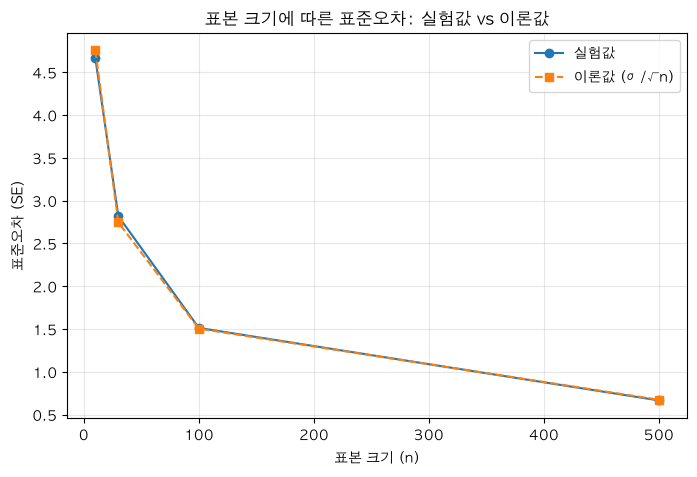

In [80]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

plt.figure(figsize=(8, 5))

plt.plot(result["표본 크기"], result["표본 평균들의 표준편차"],
         marker='o', label='실험값')
plt.plot(result["표본 크기"], result["이론적 표준오차"],
         marker='s', linestyle='--', label='이론값 (σ/√n)')

plt.title("표본 크기에 따른 표준오차: 실험값 vs 이론값")
plt.xlabel("표본 크기 (n)")
plt.ylabel("표준오차 (SE)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

In [81]:
# # [문제 3] 데이터를 어떻게 읽을까요?
# 1. 표본 크기가 작을 때 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

# 표본 크기가 10처럼 작아도 종 모양이다. 모집단이 원래 정규분포라서 표본 평균도 처음부터 종 모양이 된다. 
# 다만 넓게 퍼져 있어서 표준오차가 약 4.7로 크다. 즉 표본 평균이 모평균(100)에서 꽤 멀리 떨어질 수 있다.
# 앞의 지수분포 실험과 다른 점: 거기서는 n=5일 때 쏠린 모양이었지만, 여기서는 n=10이어도 처음부터 대칭이에요. 바뀌는 건 폭뿐이에요.

# 2. 표본 크기가 커질수록 분포는 어떻게 변하나요?

# 모양은 계속 종 모양이지만 점점 좁아지고 뾰족해진다. 표준오차가 n=10일 때 약 4.7, 30일 때 약 2.7,
#  100일 때 약 1.5, 500일 때 약 0.67로 줄어서, 표본 평균들이 모평균 100 근처에 더 촘촘히 모인다.

# 3. 실험값과 이론값은 얼마나 비슷한가요?

# 거의 같다. 모든 표본 크기에서 차이가 0.05보다 작았고, 그래프에서도 두 선이 거의 겹쳤다. 
# 직접 1000번 뽑아 구한 표준편차가 공식 σ/√n으로 계산한 값과 일치하므로, 공식만으로도 표준오차를 정확하게 예측할 수 있다.

# 차이가 조금 나는 이유는 무작위로 1000번만 뽑았기 때문이다. 반복 횟수를 늘리면 차이는 더 줄어든다.

# 4. 왜 표본 크기가 커질수록 표준오차가 작아질까요?
# 표본이 클수록 아주 큰 값과 아주 작은 값이 함께 섞여서 서로 상쇄되기 때문이다. 
# 10명만 뽑으면 우연히 높은 값만 뽑혀 평균이 크게 흔들릴 수 있지만, 500명을 뽑으면 한두 개의 튀는 값이 평균에 주는 영향이 작아진다. 
# 공식으로 보면 SE = σ/√n에서 n이 분모에 있으므로, n이 커질수록 SE는 작아진다.

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

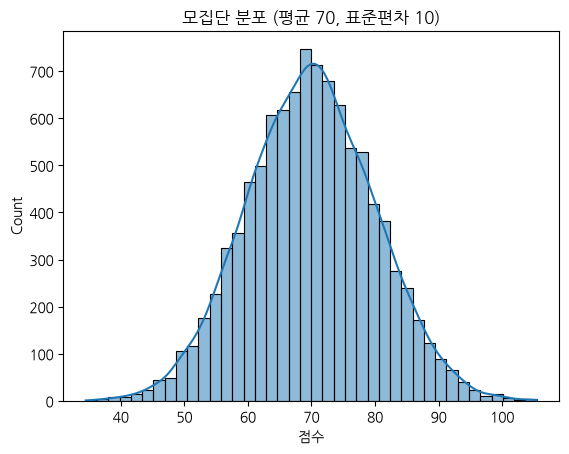

In [ ]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [82]:
import numpy as np
import pandas as pd
from scipy import stats

# 모집단 (평균 70, 표준편차 10)
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)
sigma = 10   # 모집단 표준편차를 안다고 가정 (z-분포용)

# ── 문제 1: 30명 뽑아서 평균, 표준편차, 표준오차 ──
n = 30
sample = np.random.choice(population, size=n)

mean = sample.mean()
s = sample.std(ddof=1)          # 표본 표준편차
se_z = sigma / np.sqrt(n)       # σ를 알 때 표준오차
se_t = s / np.sqrt(n)           # σ를 모를 때 표준오차

print(f"표본 평균: {mean:.2f}")
print(f"표본 표준편차: {s:.2f}")
print(f"표준오차 (σ 사용): {se_z:.3f}")
print(f"표준오차 (s 사용): {se_t:.3f}")

# ── 문제 2: 95% 신뢰구간 (z vs t) ──
z_crit = stats.norm.ppf(0.975)
t_crit = stats.t.ppf(0.975, df=n-1)

print(f"\n[95% 신뢰구간]")
print(f"z-분포: {mean - z_crit*se_z:.2f} ~ {mean + z_crit*se_z:.2f}  (임계값 {z_crit:.3f})")
print(f"t-분포: {mean - t_crit*se_t:.2f} ~ {mean + t_crit*se_t:.2f}  (임계값 {t_crit:.3f})")

# ── 문제 3: 신뢰수준 90%, 95%, 99% 비교 ──
rows = []
for level in [0.90, 0.95, 0.99]:
    alpha = 1 - level
    z = stats.norm.ppf(1 - alpha/2)
    t = stats.t.ppf(1 - alpha/2, df=n-1)
    rows.append({
        "신뢰수준": f"{int(level*100)}%",
        "z 하한": round(mean - z*se_z, 2), "z 상한": round(mean + z*se_z, 2),
        "z 폭": round(2*z*se_z, 2),
        "t 하한": round(mean - t*se_t, 2), "t 상한": round(mean + t*se_t, 2),
        "t 폭": round(2*t*se_t, 2),
    })

pd.DataFrame(rows)

표본 평균: 71.52
표본 표준편차: 9.34
표준오차 (σ 사용): 1.826
표준오차 (s 사용): 1.705

[95% 신뢰구간]
z-분포: 67.94 ~ 75.09  (임계값 1.960)
t-분포: 68.03 ~ 75.00  (임계값 2.045)


,신뢰수준,z 하한,z 상한,z 폭,t 하한,t 상한,t 폭
0,90%,68.51,74.52,6.01,68.62,74.41,5.79
1,95%,67.94,75.09,7.16,68.03,75.00,6.97
2,99%,66.81,76.22,9.41,66.82,76.22,9.40


In [83]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

import numpy as np
from scipy import stats

np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

n = 30
sample = np.random.choice(population, size=n)

mean = sample.mean()              # 표본 평균
s = sample.std(ddof=1)            # 표본 표준편차
se = s / np.sqrt(n)               # 표준오차

print(f"표본 평균: {mean:.2f}")
print(f"표본 표준편차: {s:.2f}")
print(f"표준오차: {se:.3f}")

표본 평균: 71.52
표본 표준편차: 9.34
표준오차: 1.705


In [84]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

sigma = 10                          # 모집단 표준편차 (알고 있다고 가정)
se_z = sigma / np.sqrt(n)           # σ로 계산한 표준오차
z = stats.norm.ppf(0.975)           # 95% z 임계값 (약 1.96)

lower = mean - z * se_z
upper = mean + z * se_z

print(f"z 임계값: {z:.3f}")
print(f"95% 신뢰구간 (z): {lower:.2f} ~ {upper:.2f}")

z 임계값: 1.960
95% 신뢰구간 (z): 67.94 ~ 75.09


In [85]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

t = stats.t.ppf(0.975, df=n-1)      # 95% t 임계값 (자유도 29, 약 2.045)

lower = mean - t * se
upper = mean + t * se

print(f"t 임계값: {t:.3f}")
print(f"95% 신뢰구간 (t): {lower:.2f} ~ {upper:.2f}")

t 임계값: 2.045
95% 신뢰구간 (t): 68.03 ~ 75.00


In [86]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

import pandas as pd

rows = []
for level in [0.90, 0.95, 0.99]:
    alpha = 1 - level
    z = stats.norm.ppf(1 - alpha/2)
    t = stats.t.ppf(1 - alpha/2, df=n-1)

    rows.append({
        "신뢰수준": f"{int(level*100)}%",
        "z 구간": f"{mean - z*se_z:.2f} ~ {mean + z*se_z:.2f}",
        "z 폭": round(2 * z * se_z, 2),
        "t 구간": f"{mean - t*se:.2f} ~ {mean + t*se:.2f}",
        "t 폭": round(2 * t * se, 2),
    })

pd.DataFrame(rows)

,신뢰수준,z 구간,z 폭,t 구간,t 폭
0,90%,68.51 ~ 74.52,6.01,68.62 ~ 74.41,5.79
1,95%,67.94 ~ 75.09,7.16,68.03 ~ 75.00,6.97
2,99%,66.81 ~ 76.22,9.41,66.82 ~ 76.22,9.40


**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

In [87]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 1. z-분포와 t-분포 신뢰구간은 얼마나 차이가 있나요?

# 차이가 크지 않다. 95% 기준 임계값이 z는 1.96, t는 약 2.045로 t가 조금 더 커서, t-분포 구간이 보통 약간 더 넓다. 
# t-분포는 모집단 표준편차를 모르고 표본으로 추측하기 때문에, 그 불확실성만큼 범위를 넓게 잡는다. 표본 크기가 30 정도면 둘의 차이가 작고, 표본이 커질수록 t-분포는 z-분포와 거의 같아진다.


# 2. 신뢰수준이 높아질수록 폭은 어떻게 변하나요? 왜?

# 신뢰수준이 90% → 95% → 99%로 높아질수록 구간이 넓어진다. 모평균을 더 확실하게 포함하려면 그만큼 범위를 넓게 잡아야 하기 때문이다. 
# 공식에서도 신뢰수준이 높을수록 임계값이 커져서(1.645 → 1.96 → 2.576) 오차범위가 커진다.

# 비유: 물고기를 확실히 잡고 싶으면 그물을 더 넓게 펼쳐야 해요.

# 3. 신뢰구간이 넓은 건 좋은 걸까요, 나쁜 걸까요?

# 정답이 하나가 아니에요. 장단점을 둘 다 쓰는 게 좋은 답이에요.

# 장점과 단점이 함께 있다. 구간이 넓으면 모평균이 그 안에 들어 있을 가능성은 높지만, 
# "평균이 60~80점 사이"처럼 너무 넓으면 쓸모 있는 정보가 적다. 반대로 구간이 좁으면 정밀하지만 틀릴 위험이 조금 더 크다. 
# 그래서 적절한 신뢰수준(보통 95%)을 고르고, 구간을 좁히고 싶다면 신뢰수준을 낮추기보다 표본 크기를 늘리는 것이 좋다. 표본이 커지면 표준오차가 줄어 신뢰수준을 유지하면서도 구간이 좁아진다.

# 4. 실제 고객 만족도라면, 마케팅 전략에 어떻게 활용할 수 있을까요?


# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

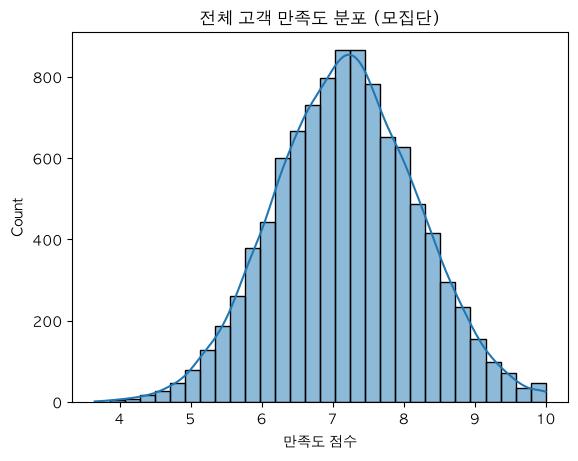

In [88]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [ ]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.

In [ ]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.

In [ ]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.

In [ ]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.